In [11]:
!pip install -q datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dataset = load_dataset("GB2024/diabetes", split="train")
df_raw = dataset.to_pandas()

print(f"Đã nạp trọn bộ: {df_raw.shape[0]:,} dòng và {df_raw.shape[1]} cột.")
display(df_raw.head(5))

diabetes_prediction_dataset.csv:   0%|          | 0.00/3.81M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Đã nạp trọn bộ: 100,000 dòng và 9 cột.


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [13]:
print(f"Tổng số dòng gốc ban đầu: {len(df_raw):,}")

#Soi dữ liệu gốc
print(f"-> Số dòng bị trùng lặp hoàn toàn (Duplicates): {df_raw.duplicated().sum():,}")
print(f"-> Số dòng bị trống (NaN) ở bmi/diabetes: {df_raw[['bmi', 'diabetes']].isna().sum().to_dict()}")
print(f"-> Số dòng dính bẫy điền giả (bmi == 27.32): {(df_raw['bmi'] == 27.32).sum():,}")
print(f"-> Số hồ sơ trẻ em (age < 18): {(df_raw['age'] < 18).sum():,}")
print(f"-> Số ca BMI phi lý (< 12 hoặc > 60): {(~df_raw['bmi'].between(12, 60)).sum():,}")

# 2. Thực hiện làm sạch từng bước
df_clean = df_raw.drop_duplicates().copy()                  # Xóa dòng trùng lặp
df_clean = df_clean[['age', 'bmi', 'diabetes']].dropna()    # Xóa dòng khuyết

# Lọc theo nghiệp vụ y khoa (Domain Knowledge)
df_clean = df_clean[
    (df_clean['age'] >= 18) &           # Chỉ lấy người trưởng thành
    (df_clean['bmi'].between(12, 60)) & # Loại bỏ ngoại lai sinh học phi lý
    (df_clean['bmi'] != 27.32)          # Loại bỏ điểm điền khuyết nhân tạo
].copy()

# 3. Chốt lại đúng 2 cột theo yêu cầu Bài 2 và reset lại chỉ mục (index)
df_bmi = df_clean[['bmi', 'diabetes']].rename(
    columns={'bmi': 'BMI', 'diabetes': 'MacBenh'}
).reset_index(drop=True)

print(f"\n==> SAU KHI LÀM SẠCH: Còn lại {len(df_bmi):,} hồ sơ bệnh nhân chuẩn.")
print("--- Tỷ lệ nhãn (0: Không bệnh, 1: Mắc bệnh) ---")
print(df_bmi['MacBenh'].value_counts(normalize=True).round(4))
display(df_bmi.describe().round(2))

Tổng số dòng gốc ban đầu: 100,000
-> Số dòng bị trùng lặp hoàn toàn (Duplicates): 3,854
-> Số dòng bị trống (NaN) ở bmi/diabetes: {'bmi': 0, 'diabetes': 0}
-> Số dòng dính bẫy điền giả (bmi == 27.32): 25,495
-> Số hồ sơ trẻ em (age < 18): 17,219
-> Số ca BMI phi lý (< 12 hoặc > 60): 198

==> SAU KHI LÀM SẠCH: Còn lại 60,331 hồ sơ bệnh nhân chuẩn.
--- Tỷ lệ nhãn (0: Không bệnh, 1: Mắc bệnh) ---
MacBenh
0    0.8864
1    0.1136
Name: proportion, dtype: float64


,BMI,MacBenh
count,60331.00,60331.00
mean,29.04,0.11
std,6.85,0.32
min,12.00,0.00
25%,24.11,0.00
50%,27.91,0.00
75%,32.67,0.00
max,60.00,1.00


In [14]:
# 1. Tách biến đầu vào X (ma trận 2D) và nhãn mục tiêu y (vector 1D)
X = df_bmi[['BMI']]
y = df_bmi['MacBenh']

# 2. Chia 80% Train - 20% Test CÓ PHÂN TẦNG (stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Tập Train: {len(X_train):,} dòng (Tỷ lệ bệnh: {y_train.mean():.2%})")
print(f"Tập Test:  {len(X_test):,} dòng (Tỷ lệ bệnh: {y_test.mean():.2%})")

# 3. Huấn luyện song song 2 mô hình để thấy rõ sự khác biệt
# Mô hình A: Mặc định (giống sách giáo khoa)
model_default = LogisticRegression(random_state=42)
model_default.fit(X_train, y_train)

# Mô hình B: Cân bằng trọng số lớp (chuẩn doanh nghiệp cho data y tế mất cân bằng)
model_balanced = LogisticRegression(class_weight='balanced', random_state=42)
model_balanced.fit(X_train, y_train)

# 4. In ra tham số phương trình Sigmoid mà 2 mô hình vừa học được
print("\n=== THAM SỐ PHƯƠNG TRÌNH SIGMOID HỌC ĐƯỢC ===")
print(f"[Mặc định]  Theta_0 (Intercept): {model_default.intercept_[0]:.4f} | Theta_1 (BMI): {model_default.coef_[0][0]:.4f}")
print(f"[Cân bằng]  Theta_0 (Intercept): {model_balanced.intercept_[0]:.4f} | Theta_1 (BMI): {model_balanced.coef_[0][0]:.4f}")

Tập Train: 48,264 dòng (Tỷ lệ bệnh: 11.36%)
Tập Test:  12,067 dòng (Tỷ lệ bệnh: 11.35%)

=== THAM SỐ PHƯƠNG TRÌNH SIGMOID HỌC ĐƯỢC ===
[Mặc định]  Theta_0 (Intercept): -4.5690 | Theta_1 (BMI): 0.0823
[Cân bằng]  Theta_0 (Intercept): -2.7896 | Theta_1 (BMI): 0.0913


=== 1. SO SÁNH DỰ ĐOÁN TRÊN 8 BỆNH NHÂN MẪU ===


,BMI,ThucTe,XS_MacDinh,Doan_MacDinh,XS_CanBang,Doan_CanBang
9959,19.98,0,0.051,0,0.276,0
5231,24.64,0,0.073,0,0.368,0
1406,25.65,0,0.079,0,0.390,0
9397,26.13,0,0.082,0,0.400,0
12010,29.55,0,0.106,0,0.477,0
783,30.71,0,0.115,0,0.503,1
5116,40.17,1,0.220,0,0.706,1
7853,45.17,0,0.299,0,0.791,1



=== 2. BÁO CÁO MÔ HÌNH MẶC ĐỊNH ===
Accuracy: 0.8847
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     10697
           1       0.28      0.01      0.02      1370

    accuracy                           0.88     12067
   macro avg       0.58      0.50      0.48     12067
weighted avg       0.82      0.88      0.83     12067

=== 3. BÁO CÁO MÔ HÌNH CÂN BẰNG (BALANCED) ===
Accuracy: 0.6684
              precision    recall  f1-score   support

           0       0.93      0.68      0.78     10697
           1       0.19      0.58      0.29      1370

    accuracy                           0.67     12067
   macro avg       0.56      0.63      0.53     12067
weighted avg       0.84      0.67      0.73     12067



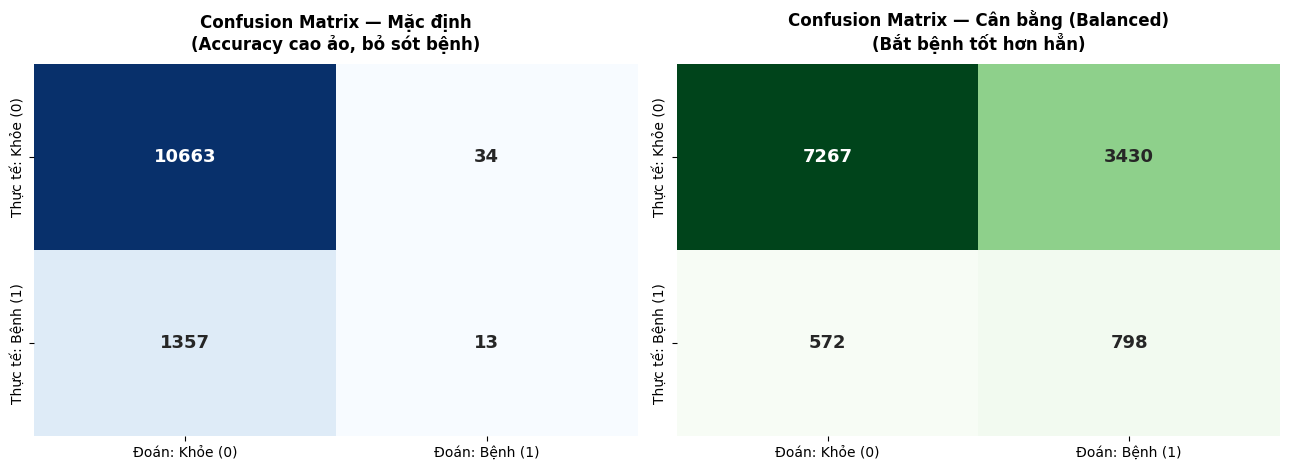

In [15]:
# 1. Dự đoán xác suất mắc bệnh (cột 1) và nhãn 0/1 trên tập Test
y_prob_def = model_default.predict_proba(X_test)[:, 1]
y_pred_def = model_default.predict(X_test)

y_prob_bal = model_balanced.predict_proba(X_test)[:, 1]
y_pred_bal = model_balanced.predict(X_test)

# 2. Soi nhanh 8 bệnh nhân mẫu để thấy rõ sự khác biệt giữa Xác suất và Nhãn
sample_view = pd.DataFrame({
    'BMI': X_test['BMI'].values,
    'ThucTe': y_test.values,
    'XS_MacDinh': np.round(y_prob_def, 3),
    'Doan_MacDinh': y_pred_def,
    'XS_CanBang': np.round(y_prob_bal, 3),
    'Doan_CanBang': y_pred_bal
}).sample(8, random_state=7).sort_values(by='BMI')

print("=== 1. SO SÁNH DỰ ĐOÁN TRÊN 8 BỆNH NHÂN MẪU ===")
display(sample_view)

# 3. In báo cáo phân loại (Accuracy, Precision, Recall, F1-Score)
print("\n=== 2. BÁO CÁO MÔ HÌNH MẶC ĐỊNH ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_def):.4f}")
print(classification_report(y_test, y_pred_def, zero_division=0))

print("=== 3. BÁO CÁO MÔ HÌNH CÂN BẰNG (BALANCED) ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bal):.4f}")
print(classification_report(y_test, y_pred_bal, zero_division=0))

# 4. Vẽ 2 Ma trận nhầm lẫn (Confusion Matrix) đặt cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, y_p, title, cmap in [
    (axes[0], y_pred_def, 'Confusion Matrix — Mặc định\n(Accuracy cao ảo, bỏ sót bệnh)', 'Blues'),
    (axes[1], y_pred_bal, 'Confusion Matrix — Cân bằng (Balanced)\n(Bắt bệnh tốt hơn hẳn)', 'Greens')
]:
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax,
                xticklabels=['Đoán: Khỏe (0)', 'Đoán: Bệnh (1)'],
                yticklabels=['Thực tế: Khỏe (0)', 'Thực tế: Bệnh (1)'],
                annot_kws={'size': 13, 'weight': 'bold'})
    ax.set_title(title, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

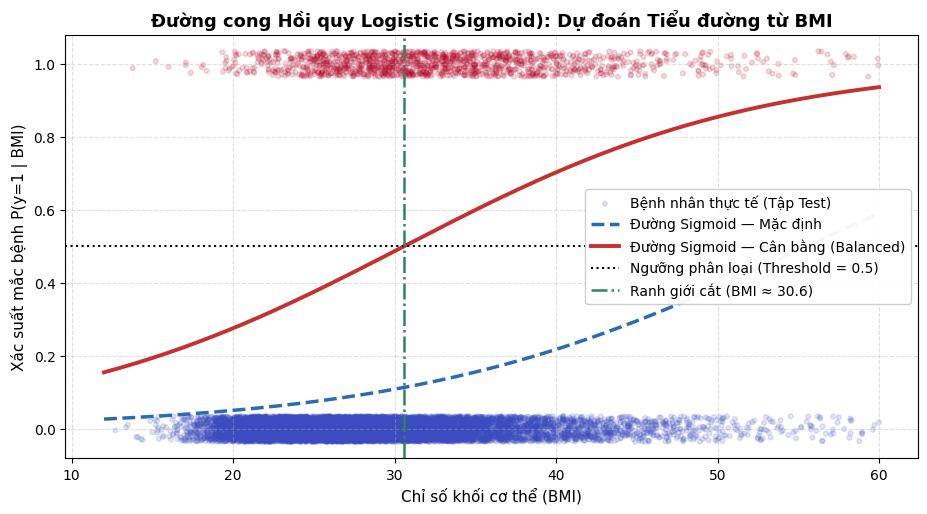

In [16]:
# 1. Tạo một dải 300 điểm BMI mượt từ 12 đến 60 để vẽ đường cong Sigmoid
bmi_grid = pd.DataFrame({'BMI': np.linspace(12, 60, 300)})
prob_curve_def = model_default.predict_proba(bmi_grid)[:, 1]
prob_curve_bal = model_balanced.predict_proba(bmi_grid)[:, 1]

# 2. Tính chính xác mốc BMI cắt ngưỡng 0.5 của mô hình Balanced
# Công thức: theta_0 + theta_1 * BMI = 0  ==>  BMI = -theta_0 / theta_1
bmi_cutoff = -model_balanced.intercept_[0] / model_balanced.coef_[0][0]

# 3. Thêm độ rung dọc nhẹ (Jitter) cho nhãn 0/1 để các điểm không đè bẹp lên nhau
np.random.seed(42)
y_jitter = y_test.values + np.random.uniform(-0.035, 0.035, size=len(y_test))

# 4. Vẽ biểu đồ
plt.figure(figsize=(11, 5.5))
plt.scatter(X_test['BMI'], y_jitter, c=y_test, cmap='coolwarm', alpha=0.15, s=12, label='Bệnh nhân thực tế (Tập Test)')

plt.plot(bmi_grid['BMI'], prob_curve_def, color='#2B6CB0', lw=2.5, linestyle='--', label='Đường Sigmoid — Mặc định')
plt.plot(bmi_grid['BMI'], prob_curve_bal, color='#C53030', lw=2.8, label='Đường Sigmoid — Cân bằng (Balanced)')

plt.axhline(0.5, color='black', linestyle=':', lw=1.5, label='Ngưỡng phân loại (Threshold = 0.5)')
plt.axvline(bmi_cutoff, color='#2F855A', linestyle='-.', lw=1.8, label=f'Ranh giới cắt (BMI ≈ {bmi_cutoff:.1f})')

plt.title('Đường cong Hồi quy Logistic (Sigmoid): Dự đoán Tiểu đường từ BMI', fontsize=13, fontweight='bold')
plt.xlabel('Chỉ số khối cơ thể (BMI)', fontsize=11)
plt.ylabel('Xác suất mắc bệnh P(y=1 | BMI)', fontsize=11)
plt.ylim(-0.08, 1.08)
plt.legend(loc='center right', framealpha=0.95)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

In [17]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
rows = []

for t in thresholds:
    # Thay vì dùng mặc định 0.5, ta tự so sánh xác suất với ngưỡng t
    y_pred_t = (y_prob_bal >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()

    acc = accuracy_score(y_test, y_pred_t)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    rows.append({
        'Ngưỡng (Threshold)': t,
        'Accuracy': round(acc, 4),
        'Precision (Độ chuẩn)': round(precision, 4),
        'Recall (Bắt trúng bệnh)': round(recall, 4),
        'Báo nhầm (FP)': fp,
        'Bỏ sót bệnh (FN)': fn
    })

df_thresh = pd.DataFrame(rows)
print("=== BẢNG SO SÁNH KHI THAY ĐỔI NGƯỠNG XÁC SUẤT (MÔ HÌNH BALANCED) ===")
display(df_thresh)

=== BẢNG SO SÁNH KHI THAY ĐỔI NGƯỠNG XÁC SUẤT (MÔ HÌNH BALANCED) ===


,Ngưỡng (Threshold),Accuracy,Precision (Độ chuẩn),Recall (Bắt trúng bệnh),Báo nhầm (FP),Bỏ sót bệnh (FN)
0,0.3,0.2023,0.1220,0.9723,9588,38
1,0.4,0.4486,0.1494,0.8219,6410,244
2,0.5,0.6684,0.1887,0.5825,3430,572
3,0.6,0.7869,0.2171,0.3365,1662,909
4,0.7,0.8454,0.2392,0.1657,722,1143
